# Portfolio Optimization with Absolute-Deviation Risk

## 1. Introduction

This project investigates how long-only portfolios constructed to minimize
absolute-deviation risk perform outside the estimation sample.

Using daily adjusted equity prices for 2022–2023, we compute simple returns,
examine their descriptive statistics, and split the sample chronologically
into training and test periods.

Portfolio weights are estimated using only the training sample and then
applied to the test sample. The analysis compares in-sample and
out-of-sample risk and median daily returns across different allocation
targets.

The investment universe consists of S&P 500 constituents available at the
time of data retrieval, rather than historical index membership. This
limitation is discussed alongside the empirical results.

## 2. Data Collection

We retrieve the S&P 500 constituent list from the main branch of the
datasets/s-and-p-500-companies GitHub repository and obtain daily adjusted
closing prices for 2022–2023 through Yahoo Finance, using yfinance.
Adjusted prices account for stock splits and dividends.

The constituent list reflects the version maintained by the source
repository when accessed, rather than historical membership during
2022–2023. The analysis therefore uses a retrospectively selected universe
and should not be interpreted as a point-in-time backtest.

In [50]:
%pip install -q yfinance

In [51]:
import numpy as np
import pandas as pd
import yfinance as yf
from IPython.display import display

START_DATE = "2022-01-01"
END_DATE = "2024-01-01"  # Exclusive: includes 2022 and 2023 only

CONSTITUENTS_URL = (
    "https://raw.githubusercontent.com/"
    "datasets/s-and-p-500-companies/main/data/constituents.csv"
)

constituents = pd.read_csv(CONSTITUENTS_URL)

tickers = sorted(
    constituents["Symbol"]
    .str.replace(".", "-", regex=False)
    .dropna()
    .unique()
    .tolist()
)

downloaded_at = pd.Timestamp.now(tz="UTC").isoformat()

download = yf.download(
    tickers=tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)

if download is None or download.empty:
    raise RuntimeError("No price data downloaded. Check the connection and retry.")

prices = (
    download["Close"]
    .reindex(columns=tickers)
    .sort_index()
)

assert prices.index.is_unique, "Duplicate dates found."

print(f"Download timestamp: {downloaded_at}")
print(f"Requested tickers: {len(tickers)}")

ERROR:yfinance:
8 Failed downloads:
ERROR:yfinance:['HONA', 'FDXF', 'SOLV', 'SNDK', 'GEV', 'RDDT', 'Q', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2022-01-01 -> 2024-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1641013200, endDate = 1704085200")')


Download timestamp: 2026-10-22T20:29:08.759504+00:00
Requested tickers: 503


## 3. Data Inspection

We inspect the sample dates, dataset dimensions, and availability of prices
for each ticker.

Missing observations may reflect download failures, listings after the sample
start, or corporate events. They are reported rather than automatically filled.

Asset eligibility will be determined using the training sample after the
chronological split, without requiring complete data over the test period.

In [52]:
availability = pd.DataFrame({
    "available_prices": prices.notna().sum(),
    "missing_prices": prices.isna().sum(),
})

availability["missing_share"] = (
    availability["missing_prices"] / len(prices)
)

unavailable = availability.index[
    availability["available_prices"].eq(0)
].tolist()

print(f"Price dataset: {prices.shape[0]} dates × {prices.shape[1]} tickers")
print(f"Sample: {prices.index.min().date()} to {prices.index.max().date()}")
print(f"Tickers without any prices: {len(unavailable)}")

if unavailable:
    print("Unavailable tickers:", ", ".join(unavailable))

display(prices.iloc[:5, :8])

display(
    availability
    .sort_values("missing_share", ascending=False)
    .head(10)
)

Price dataset: 501 dates × 503 tickers
Sample: 2022-01-03 to 2023-12-29
Tickers without any prices: 8
Unavailable tickers: FDXF, GEV, HONA, Q, RDDT, SNDK, SOLV, VYLR


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE
Date,,,,,,,,
2022-01-03,151.185501,177.786362,113.385818,172.679993,125.867706,42.362530,372.972595,564.369995
2022-01-04,146.074509,175.529984,113.168114,170.800003,122.907516,42.914051,370.307251,554.000000
2022-01-05,143.572144,170.860947,113.762566,162.250000,122.355316,42.410072,363.785858,514.429993
2022-01-06,144.074539,168.008682,113.226700,159.750000,122.337181,42.657307,346.218475,514.119995
2022-01-07,140.238861,168.174759,112.933640,166.050003,122.717407,42.856995,339.578064,510.700012


,available_prices,missing_prices,missing_share
Ticker,,,
GEV,0,501,1.000000
SNDK,0,501,1.000000
VYLR,0,501,1.000000
RDDT,0,501,1.000000
SOLV,0,501,1.000000
FDXF,0,501,1.000000
HONA,0,501,1.000000
Q,0,501,1.000000
VLTO,61,440,0.878244


In [53]:
print(f"Trading dates: {len(prices):,}")
print(f"Requested tickers: {prices.shape[1]:,}")
print(f"Tickers with available prices: {prices.notna().any().sum():,}")
print(f"Tickers with complete price histories: {prices.notna().all().sum():,}")
print(f"Tickers with partial price histories: {(prices.notna().any() & prices.isna().any()).sum():,}")
print(f"Tickers without price data: {prices.isna().all().sum():,}")
print(f"Total observed prices: {prices.notna().sum().sum():,}")

Trading dates: 501
Requested tickers: 503
Tickers with available prices: 495
Tickers with complete price histories: 491
Tickers with partial price histories: 4
Tickers without price data: 8
Total observed prices: 246,969


Most tickers have complete price histories over the selected period.
Four tickers have partial coverage, while eight have no price observations
in the downloaded dataset.

Missing values are retained at this stage. Asset eligibility will be
determined using only the training sample after the chronological split.

## 4. Simple Returns

Daily simple returns are computed from adjusted closing prices:

$$
r_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1.
$$

Returns are expressed in decimal units: a value of 0.01 corresponds to 1%.

Missing prices are not forward-filled. Consequently, a return remains missing
when either of the two required consecutive prices is unavailable.

The first price observation is used to initialize the calculation and does
not produce a return.

In [54]:
returns = prices.pct_change(fill_method=None).iloc[1:].copy()

# Infinite returns would indicate invalid input prices.
if np.isinf(returns.to_numpy()).any():
    raise ValueError("Infinite returns detected. Inspect the price data.")

print(f"Return dataset: {returns.shape[0]} dates × {returns.shape[1]} tickers")
print(f"Missing return observations: {int(returns.isna().sum().sum())}")

display(returns.iloc[:5, :8])

Return dataset: 500 dates × 503 tickers
Missing return observations: 5026


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE
Date,,,,,,,,
2022-01-04,-0.033806,-0.012692,-0.001920,-0.010887,-0.023518,0.013019,-0.007146,-0.018374
2022-01-05,-0.017131,-0.026600,0.005253,-0.050059,-0.004493,-0.011744,-0.017611,-0.071426
2022-01-06,0.003499,-0.016693,-0.004710,-0.015408,-0.000148,0.005830,-0.048290,-0.000603
2022-01-07,-0.026623,0.000989,-0.002588,0.039437,0.003108,0.004681,-0.019180,-0.006652
2022-01-10,0.000069,0.000116,0.011195,-0.032159,-0.002213,0.021078,0.006069,0.029626


## 5. Descriptive Statistics

We summarize the daily returns over the full 2022–2023 sample using the mean, median,
standard deviation, minimum, maximum, skewness, and excess kurtosis.

The mean and median describe the location of the return distribution,
while standard deviation measures dispersion. Skewness describes asymmetry.
Excess kurtosis measures the standardized fourth moment relative to the
normal distribution, for which it equals zero.

All return and volatility statistics are reported in daily decimal units.
Skewness and excess kurtosis are dimensionless.

In [55]:
desc = returns.describe().rename(index={"50%": "median"})
desc.loc["skewness"] = returns.skew()
desc.loc["excess kurtosis"] = returns.kurt()

display(desc)

Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,...,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,-0.000015,0.000302,0.000514,0.000069,-0.000285,0.001164,-0.000082,0.000419,0.000505,0.000354,...,0.000056,0.000517,0.000027,0.001236,0.000184,-0.000466,0.000071,0.000107,-0.001128,-0.000144
std,0.019747,0.018316,0.013257,0.032959,0.014805,0.016851,0.017711,0.024657,0.020106,0.017108,...,0.017441,0.029317,0.013451,0.019198,0.018757,0.045749,0.012911,0.016376,0.027671,0.018088
min,-0.065824,-0.058680,-0.079914,-0.134250,-0.065441,-0.068310,-0.059191,-0.167932,-0.078331,-0.073357,...,-0.063657,-0.122452,-0.051517,-0.078853,-0.120272,-0.156061,-0.045844,-0.090858,-0.172717,-0.110070
25%,-0.011722,-0.009659,-0.006273,-0.019917,-0.009316,-0.007626,-0.010204,-0.012478,-0.011677,-0.007814,...,-0.010548,-0.015417,-0.007790,-0.010250,-0.009910,-0.026751,-0.007582,-0.008395,-0.016271,-0.011394
median,-0.000321,0.000573,0.000802,-0.000792,-0.000237,0.001257,-0.000035,0.000076,0.000620,0.001257,...,0.000000,0.000616,-0.000073,0.001599,0.000208,-0.001287,0.000891,-0.001153,-0.000325,-0.000585
75%,0.012045,0.010124,0.008102,0.019755,0.007579,0.011384,0.010302,0.015607,0.012353,0.010084,...,0.009928,0.014535,0.008520,0.012768,0.010600,0.023959,0.007826,0.008514,0.014881,0.011179
max,0.087208,0.088975,0.048978,0.133532,0.078157,0.096537,0.077240,0.103992,0.081900,0.057042,...,0.093147,0.131660,0.053345,0.064113,0.096273,0.261396,0.042739,0.073520,0.116978,0.070887
skewness,0.382506,0.172745,-0.830280,-0.104826,0.158382,0.126001,0.012712,-0.685508,0.062488,-0.660556,...,0.294413,0.335050,-0.032546,-0.139454,-0.353714,0.438412,-0.187507,-0.002033,-0.743924,-0.082953
excess kurtosis,1.659069,2.048750,4.540085,1.261431,2.375450,2.868198,1.576100,5.183677,1.209379,2.011787,...,2.220321,2.997124,1.148670,1.027895,4.878457,2.758307,0.673777,3.466798,5.805507,3.317939


## 6. Train/Test Split and Asset Selection

We split the daily returns chronologically: the first 70% of observations
form the training sample, while the remaining 30% form the test sample.

Only assets with complete return histories in the training sample are
retained for portfolio construction. The same assets are kept in the test
sample, preserving their column order.

Test-sample data availability does not influence asset selection. Any
remaining missing test returns are reported before portfolio evaluation.

In [56]:
# Split chronologically: 70% training, 30% testing
split_idx = int(len(returns) * 0.70)

train_raw = returns.iloc[:split_idx].copy()
test_raw = returns.iloc[split_idx:].copy()

# Select assets using training data only
eligible_assets = train_raw.columns[
    train_raw.notna().all()
]

returns_train = train_raw.loc[:, eligible_assets].copy()
returns_test = test_raw.loc[:, eligible_assets].copy()

# Summarize the two samples
split_summary = pd.DataFrame({
    "Sample": ["Train", "Test"],
    "Start date": [
        returns_train.index.min().date(),
        returns_test.index.min().date(),
    ],
    "End date": [
        returns_train.index.max().date(),
        returns_test.index.max().date(),
    ],
    "Observations": [
        len(returns_train),
        len(returns_test),
    ],
    "Assets": [
        returns_train.shape[1],
        returns_test.shape[1],
    ],
    "Missing returns": [
        int(returns_train.isna().sum().sum()),
        int(returns_test.isna().sum().sum()),
    ],
}).set_index("Sample")

display(split_summary)

print(f"Assets excluded using training data: "
      f"{returns.shape[1] - len(eligible_assets)}")

,Start date,End date,Observations,Assets,Missing returns
Sample,,,,,
Train,2022-01-04,2023-05-25,350,491,0
Test,2023-05-26,2023-12-29,150,491,0


Assets excluded using training data: 12


## 7. Portfolio Optimization

### 7.1. Mathematical Formulation

We construct fully invested, long-only portfolios using the training sample.

Let $r_{i,t}$ denote the daily return of asset $i$ and $w_i$ its portfolio
weight. The portfolio return on day $t$ is:

$$
r_{p,t}(w) = \sum_{i=1}^{n} w_i r_{i,t}.
$$

We measure risk using the mean absolute deviation from the portfolio's
sample median:

$$
A(w) =
\frac{1}{T}
\sum_{t=1}^{T}
\left|
r_{p,t}(w) -
\operatorname{median}_{s=1,\ldots,T} r_{p,s}(w)
\right|.
$$

This measure is distinct from the median absolute deviation.

For each asset, let $m_i$ be its median daily return in the training sample.
We define a linear allocation score:

$$
s(w) = \sum_{i=1}^{n} w_i m_i.
$$

This score is the weighted average of individual asset medians.
It is not generally equal to the median of portfolio returns.

For each target score $s_k$, we solve:

$$
\begin{aligned}
\min_w \quad & A(w) \\
\text{subject to} \quad
& \sum_{i=1}^{n} w_i = 1, \\
& w_i \geq 0 \quad \text{for all } i, \\
& \sum_{i=1}^{n} w_i m_i = s_k.
\end{aligned}
$$

We consider ten equally spaced target scores between the minimum and
maximum individual asset medians in the training sample.

For each resulting portfolio, we report both the allocation score and
the actual median portfolio return.

### 7.2. Portfolio Construction

The optimization problem can be expressed as a linear program by introducing
a free center $c$ and nonnegative absolute-deviation variables $u_t$:

$$
\begin{aligned}
\min_{w,c,u}\quad & \frac{1}{T}\sum_{t=1}^{T}u_t\\
\text{subject to}\quad
& u_t \geq r_{p,t}(w)-c,\\
& u_t \geq c-r_{p,t}(w),\\
& \sum_{i=1}^{n}w_i=1,\\
& \sum_{i=1}^{n}w_i m_i=s_k,\\
& w_i\geq0,\quad u_t\geq0.
\end{aligned}
$$

For any fixed portfolio, a sample median minimizes the sum of absolute
deviations. Optimizing over the center therefore preserves the risk
objective defined above.

We solve this linear program for each of the ten target allocation scores
using the HiGHS solver through SciPy.

In [57]:
from scipy.optimize import linprog
from scipy.sparse import csr_matrix, eye, hstack, vstack

# Training returns and individual asset medians
R_train = returns_train.to_numpy(dtype=float)
T, n = R_train.shape
asset_medians = np.median(R_train, axis=0)

assert np.isfinite(R_train).all(), "Training returns must be finite."

target_scores = np.linspace(
    asset_medians.min(),
    asset_medians.max(),
    10,
)

# Decision variables: [portfolio weights, center, absolute deviations]
objective = np.concatenate([
    np.zeros(n + 1),
    np.full(T, 1 / T),
])

# Absolute-deviation constraints:
# Rw - c - u <= 0
# -Rw + c - u <= 0
A_ub = vstack([
    hstack([
        csr_matrix(R_train),
        csr_matrix(-np.ones((T, 1))),
        -eye(T),
    ]),
    hstack([
        csr_matrix(-R_train),
        csr_matrix(np.ones((T, 1))),
        -eye(T),
    ]),
], format="csr")

b_ub = np.zeros(2 * T)

# Equality constraints: sum of weights = 1; allocation score = target
A_eq = csr_matrix(np.vstack([
    np.concatenate([np.ones(n), np.zeros(T + 1)]),
    np.concatenate([asset_medians, np.zeros(T + 1)]),
]))

# Nonnegative weights, unrestricted center, nonnegative deviations
bounds = (
    [(0, None)] * n
    + [(None, None)]
    + [(0, None)] * T
)

optimization_results = []
weights_list = []

for k, target in enumerate(target_scores, start=1):
    result = linprog(
        c=objective,
        A_ub=A_ub,
        b_ub=b_ub,
        A_eq=A_eq,
        b_eq=np.array([1.0, target]),
        bounds=bounds,
        method="highs",
    )

    if not result.success:
        raise RuntimeError(
            f"Portfolio {k}: optimization failed — {result.message}"
        )

    optimization_results.append(result)
    weights_list.append(result.x[:n].copy())

print(f"Portfolios successfully optimized: {len(weights_list)}")
print(f"Assets per portfolio: {n}")
print(f"Training observations: {T}")

Portfolios successfully optimized: 10
Assets per portfolio: 491
Training observations: 350


### 7.3 Optimization Diagnostics

For each portfolio, we verify that the weights sum to one, satisfy the long-only constraint, and achieve the target score. We also compare the solver objective with the absolute-deviation risk computed directly from portfolio returns.

In [58]:
diagnostics = []

for k, (target, weights, result) in enumerate(
    zip(target_scores, weights_list, optimization_results), start=1
):
    portfolio_returns = R_train @ weights
    portfolio_median = np.median(portfolio_returns)
    risk = np.mean(np.abs(portfolio_returns - portfolio_median))

    diagnostics.append({
        "Portfolio": f"P{k:02d}",
        "Weight sum": weights.sum(),
        "Minimum weight": weights.min(),
        "Target score": target,
        "Achieved score": weights @ asset_medians,
        "Target error": abs(weights @ asset_medians - target),
        "Objective error": abs(risk - result.fun),
    })

diagnostics = pd.DataFrame(diagnostics).set_index("Portfolio")

assert np.allclose(
    diagnostics["Weight sum"], 1.0, atol=1e-8, rtol=0
), "Some portfolio weights do not sum to one."

assert (
    diagnostics["Minimum weight"] >= -1e-10
).all(), "Negative portfolio weights detected."

assert (
    diagnostics["Target error"] <= 1e-8
).all(), "Some portfolios do not satisfy the target-score constraint."

assert (
    diagnostics["Objective error"] <= 1e-8
).all(), "Solver objectives differ from directly computed risk."

display(diagnostics)

,Weight sum,Minimum weight,Target score,Achieved score,Target error,Objective error
Portfolio,,,,,,
P01,1.0,0.0,-0.011947,-0.011947,0.000000e+00,5.551115e-17
P02,1.0,0.0,-0.010286,-0.010286,1.734723e-18,6.938894e-18
P03,1.0,0.0,-0.008625,-0.008625,0.000000e+00,6.938894e-18
P04,1.0,0.0,-0.006965,-0.006965,0.000000e+00,6.938894e-18
P05,1.0,0.0,-0.005304,-0.005304,2.602085e-18,1.040834e-17
P06,1.0,0.0,-0.003643,-0.003643,8.673617e-19,6.938894e-18
P07,1.0,0.0,-0.001982,-0.001982,2.168404e-18,0.000000e+00
P08,1.0,0.0,-0.000321,-0.000321,8.131516e-19,4.336809e-18
P09,1.0,0.0,0.001340,0.001340,0.000000e+00,1.734723e-18


## 8. Portfolio Results

In [59]:
portfolio_ids = [
    f"P{k:02d}" for k in range(1, len(weights_list) + 1)
]

# Rows represent assets; columns represent portfolios.
W = np.column_stack(weights_list)

# Rows represent trading dates; columns represent portfolios.
portfolio_returns_train = pd.DataFrame(
    R_train @ W,
    index=returns_train.index,
    columns=portfolio_ids,
)

portfolio_medians = portfolio_returns_train.median()

portfolio_risks = (
    portfolio_returns_train
    .sub(portfolio_medians, axis="columns")
    .abs()
    .mean()
)

train_results = pd.DataFrame({
    "Target score": target_scores,
    "Median daily return": portfolio_medians,
    "Absolute-deviation risk": portfolio_risks,
})

train_results.index.name = "Portfolio"

display(
    train_results.style.format({
        "Target score": "{:.3%}",
        "Median daily return": "{:.3%}",
        "Absolute-deviation risk": "{:.3%}",
    })
)

,Target score,Median daily return,Absolute-deviation risk
Portfolio,,,
P01,-1.195%,-1.195%,7.160%
P02,-1.029%,-1.048%,5.750%
P03,-0.863%,-0.783%,4.448%
P04,-0.696%,-0.449%,3.236%
P05,-0.530%,-0.404%,2.144%
P06,-0.364%,-0.126%,1.356%
P07,-0.198%,-0.013%,0.833%
P08,-0.032%,0.033%,0.581%
P09,0.134%,0.112%,0.617%


The endpoint targets restrict allocation to assets attaining the minimum
or maximum individual training median. If each extreme is unique, P01
and P10 are single-asset portfolios.

The target score can differ materially from the actual portfolio median.
For example, P04 has a target score of −0.696% and a realized training
median of −0.449%, a difference of 0.247 percentage points per day.

P01–P07 are dominated by P08 in the training sample: each has higher
absolute-deviation risk and a lower median return. The full set of ten
portfolios should therefore not be interpreted as an efficient frontier.

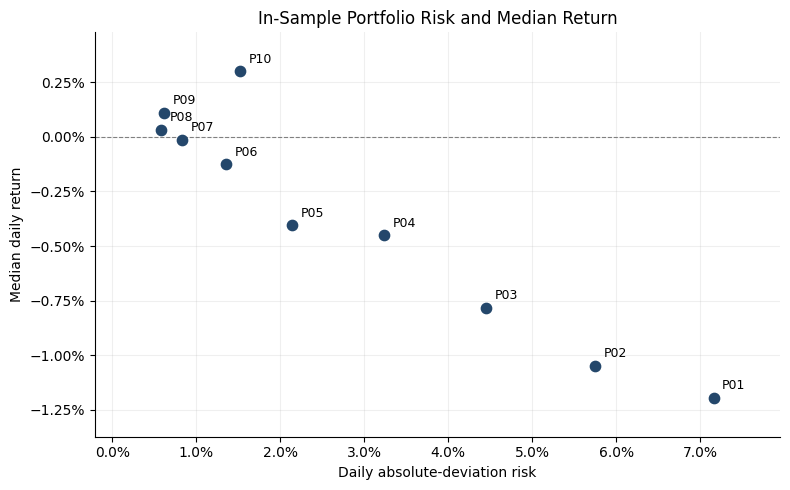

In [60]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    train_results["Absolute-deviation risk"],
    train_results["Median daily return"],
    color="#24476B",
    s=55,
    zorder=3,
)

for portfolio, row in train_results.iterrows():
    ax.annotate(
        portfolio,
        (
            row["Absolute-deviation risk"],
            row["Median daily return"],
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
    )

ax.set(
    title="In-Sample Portfolio Risk and Median Return",
    xlabel="Daily absolute-deviation risk",
    ylabel="Median daily return",
)

ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(0.12)

plt.tight_layout()
plt.show()

## 9. Out-of-Sample Evaluation

The portfolio weights estimated on the training sample are applied to the test sample without re-estimation. We compare median daily returns and absolute-deviation risk across the two periods.

Risk is measured around each portfolio's median return within the corresponding sample. Constant portfolio weights imply daily rebalancing; transaction costs are excluded.

The evaluation is out-of-sample with respect to weight estimation, but
not universe selection: the asset universe is based on a constituent
list retrieved after the evaluation period.

In [61]:
# Ensure that assets appear in the same order in both samples.
assert returns_test.columns.equals(returns_train.columns)

R_test = returns_test.to_numpy(dtype=float)

if not np.isfinite(R_test).all():
    raise ValueError("Test returns contain missing or infinite values.")

portfolio_returns_test = pd.DataFrame(
    R_test @ W,
    index=returns_test.index,
    columns=portfolio_ids,
)

test_medians = portfolio_returns_test.median()

test_risks = (
    portfolio_returns_test
    .sub(test_medians, axis="columns")
    .abs()
    .mean()
)

test_results = pd.DataFrame({
    "Median daily return": test_medians,
    "Absolute-deviation risk": test_risks,
})
test_results.index.name = "Portfolio"

comparison = pd.DataFrame({
    "Train median": train_results["Median daily return"],
    "Test median": test_results["Median daily return"],
    "Train risk": train_results["Absolute-deviation risk"],
    "Test risk": test_results["Absolute-deviation risk"],
})

display(comparison.style.format("{:.3%}"))

,Train median,Test median,Train risk,Test risk
Portfolio,,,,
P01,-1.195%,-0.284%,7.160%,5.792%
P02,-1.048%,-0.303%,5.750%,4.567%
P03,-0.783%,-0.329%,4.448%,3.545%
P04,-0.449%,-0.233%,3.236%,2.605%
P05,-0.404%,-0.085%,2.144%,1.755%
P06,-0.126%,0.147%,1.356%,1.193%
P07,-0.013%,0.020%,0.833%,0.700%
P08,0.033%,0.015%,0.581%,0.506%
P09,0.112%,0.049%,0.617%,0.487%


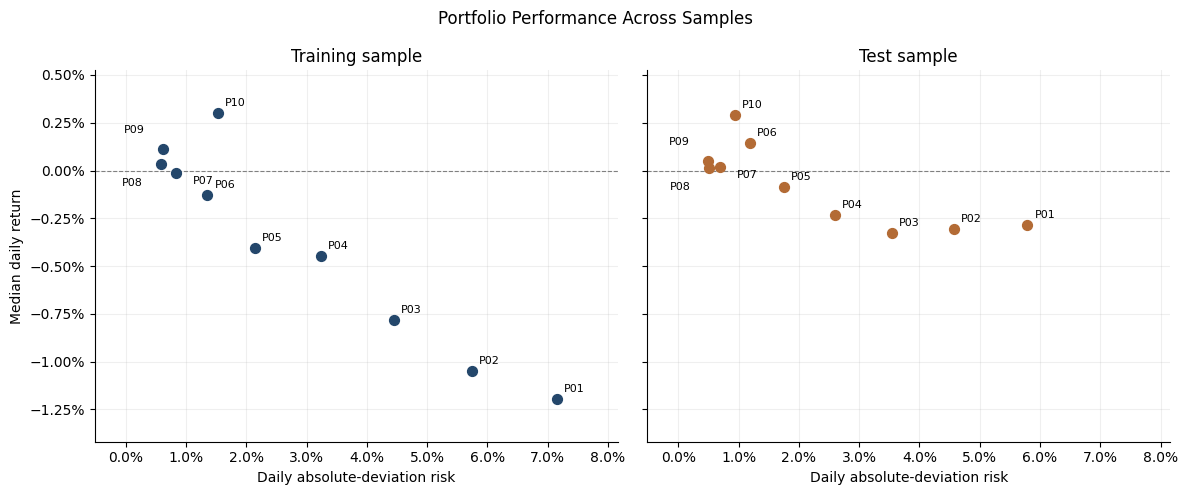

In [62]:
fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), sharex=True, sharey=True
)

offsets = {
    "P07": (12, -8),
    "P08": (-28, -16),
    "P09": (-28, 12),
}

for ax, results, title, color in zip(
    axes,
    [train_results, test_results],
    ["Training sample", "Test sample"],
    ["#24476B", "#B36B35"],
):
    ax.scatter(
        results["Absolute-deviation risk"],
        results["Median daily return"],
        color=color,
        s=50,
        zorder=3,
    )

    for portfolio, row in results.iterrows():
        ax.annotate(
            portfolio,
            (
                row["Absolute-deviation risk"],
                row["Median daily return"],
            ),
            xytext=offsets.get(portfolio, (5, 5)),
            textcoords="offset points",
            fontsize=8,
        )

    ax.set_title(title)
    ax.set_xlabel("Daily absolute-deviation risk")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(0.15)

axes[0].set_ylabel("Median daily return")

fig.suptitle("Portfolio Performance Across Samples")
plt.tight_layout()
plt.show()

Absolute-deviation risk is lower in the test sample for all ten portfolios,
while changes in median daily returns vary across portfolios. P01–P07 have
higher median returns in the test period, whereas P08–P10 have lower medians.

The risk ranking also changes: P08 has the lowest risk among the ten portfolios in the training sample, while P09 has the lowest risk in the test sample. The ordering of portfolio medians does not fully persist either; for example, P06 has a higher test-sample median than P09 despite its lower training target score.

These results describe differences between the two sample periods. They do not, by themselves, establish overfitting or identify the causes of the observed changes.

## 10. Portfolio Composition

We examine the portfolio with the lowest training-sample absolute-deviation risk among the ten optimized portfolios. The table displays holdings with weights above 1%.

In [63]:
portfolio_id = train_results["Absolute-deviation risk"].idxmin()
portfolio_idx = portfolio_ids.index(portfolio_id)

weights = pd.Series(
    weights_list[portfolio_idx],
    index=returns_train.columns,
    name="Weight",
)

holdings = (
    weights[weights > 0.01]
    .sort_values(ascending=False)
    .to_frame()
)

print(f"Portfolio: {portfolio_id}")
print(f"Holdings with weight above 1%: {len(holdings)}")
print(f"Weight displayed: {holdings['Weight'].sum():.2%}")

display(holdings.style.format({"Weight": "{:.2%}"}))

Portfolio: P08
Holdings with weight above 1%: 19
Weight displayed: 96.37%


,Weight
Ticker,
JNJ,15.78%
BMY,11.44%
CHD,7.27%
HRL,7.25%
LMT,6.90%
SJM,6.82%
HSY,6.23%
FOX,5.13%
CME,3.87%


P08 allocates 96.37% of its capital to 19 holdings with individual weights above 1%. The largest positions are JNJ (15.78%) and BMY (11.44%), together accounting for 27.22% of the portfolio. The remaining 3.63% is allocated to positions with individual weights at or below 1%.

Despite the availability of 491 eligible assets, the allocation is uneven, with substantial exposure to a small number of holdings. These weights minimize training-sample absolute-deviation risk subject to P08's target-score constraint; they do not imply that the largest holdings are individually the least risky assets.

## 11. Discussion and Limitations

The analysis constructs ten long-only portfolios by minimizing mean
absolute deviation around the portfolio median, subject to equally
spaced target scores. P08 has the lowest training-sample risk among
these portfolios. Applying the same weights to the test sample produces
lower risk for all ten portfolios, while changes in median returns are
mixed and portfolio rankings are not fully preserved.

The target score is a weighted average of individual asset medians,
not the median of portfolio returns. The optimization therefore solves
a different problem from directly imposing a target portfolio median.
This distinction is reflected in the reported results. Several
portfolios are dominated in terms of training-sample risk and median
return, so the full set should not be interpreted as an efficient frontier.

The asset universe is based on the constituent list maintained by the
source repository when accessed, rather than historical membership
during 2022–2023. This introduces retrospective selection and
survivorship bias. Requiring complete training histories further
restricts the universe. Subsequent downloads may also produce different
results because of constituent changes, data revisions, or download
availability.

The evaluation uses a single chronological split and provides a
descriptive comparison across two periods. Statistical uncertainty in
median returns and portfolio rankings has not been quantified.
Observed differences therefore do not establish statistically
significant performance differences or stability across other samples
and market conditions.

Absolute-deviation risk treats positive and negative deviations
symmetrically and penalizes their magnitude linearly. Extreme returns
contribute to this measure, but it does not specifically measure
downside tail losses. Minimizing it therefore does not guarantee
protection against extreme losses.

Finally, portfolio returns assume daily rebalancing to constant
weights and exclude transaction costs, which would affect the
performance of an implemented strategy.